# RL Final Project

In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

class MazeEnv(gym.Env):
    def __init__(self):
        super(MazeEnv, self).__init__()
        self.maze = np.array([
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
            [1, 10, 1, 0, 0, 0, 1, 0, 0, 1],
            [1, 0, 1, 0, 1, 0, 1, 0, 1, 1],
            [1, 0, 0, 0, 1, 0, 0, 0, 0, 1],
            [1, 1, 1, 0, 1, 1, 1, 1, 0, 1],
            [1, 0, 1, 0, 0, 0, 0, 1, 0, 1],
            [1, 0, 0, 0, 1, 1, 0, 0, 0, 1],
            [1, 1, 1, 0, 1, 0, 1, 1, 0, 1],
            [1, 0, 0, 0, 0, 0, 1, 100, 0, 1],
            [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
        ])

        self.start_pos = [1, 1]
        self.goal_pos = [8, 7]
        self.sub_goal_pos = [5, 3]
        self.agent_pos = self.start_pos

        self.action_space = spaces.Discrete(4)  # 4 possible actions: up, down, left, right

        # Flatten the 10x10 maze into a 1D array of 100 states (0 to 99)
        self.num_states = self.maze.shape[0] * self.maze.shape[1]
        self.observation_space = spaces.Discrete(self.num_states)

        self.reset()

    def reset(self):
        self.agent_pos = self.start_pos
        return self._get_obs()

    def step(self, action):

        next_pos = list(self.agent_pos)


        # Up, Down, Left, Right
        if action == 0:  # Up
            next_pos[0] -= 1
        elif action == 1:  # Down
            next_pos[0] += 1
        elif action == 2:  # Left
            next_pos[1] -= 1
        elif action == 3:  # Right
            next_pos[1] += 1


        valid = self._is_valid_move(next_pos)
        if valid == True:
            self.agent_pos = next_pos

        done = False
        reward = -1  # Default penalty for each move

        if self.agent_pos == self.sub_goal_pos:
            reward = 2  # Reward for reaching sub-goal
        if self.agent_pos == self.goal_pos:
            reward = 100  # Reward for reaching final goal
            done = True

        return self._get_obs(), reward, done

    def _get_obs(self):
        """Returns the current state as a unique integer for the Q-table."""
        # Convert (row, col) position to a single integer
        state = self._pos_to_state(self.agent_pos)
        return state

    def _is_valid_move(self, pos):
        """Checks if the move is within bounds and not a wall."""
        if 0 <= pos[0] < self.maze.shape[0] and 0 <= pos[1] < self.maze.shape[1]:
            boolean_value = self.maze[tuple(pos)]
            if boolean_value == 1:
                return False
            else:
                return True
        return True

    def _pos_to_state(self, pos):
        """Converts a (row, col) position to a unique state index."""
        return pos[0] * self.maze.shape[1] + pos[1]

    def _state_to_pos(self, state):
        """Converts a state index back to a (row, col) position."""
        row = state // self.maze.shape[1]
        col = state % self.maze.shape[1]
        return [row, col]

    def render(self):
        """Renders the maze with the agent, start, sub-goal, and end goal."""
        maze_to_render = np.copy(self.maze)

        # Replace markers for rendering (we'll use text annotations for 'S', 'G', 'E')
        maze_to_render[maze_to_render == 10] = 0  # Replace 'S' with 0 (empty space)
        maze_to_render[maze_to_render == 50] = 0  # Replace 'G' with 0
        maze_to_render[maze_to_render == 100] = 0  # Replace 'E' with 0
        maze_to_render = maze_to_render.astype(int)  # Convert to integer array

        # Mark agent's position with a different integer (e.g., 2)
        maze_to_render[tuple(self.agent_pos)] = 2  # Agent's position (marked with 2)

        # Render using imshow
        plt.imshow(maze_to_render, cmap="Greys", origin="upper")
        
        # Add text labels for start, sub-goal, and end goal
        plt.text(1, 1, 'S', ha='center', va='center', color='black', fontsize=12)  # Start
        plt.text(3, 5, 'G', ha='center', va='center', color='black', fontsize=12)  # Sub-goal
        plt.text(7, 8, 'E', ha='center', va='center', color='black', fontsize=12)  # End
        
        plt.title("Maze Environment")
        plt.show()




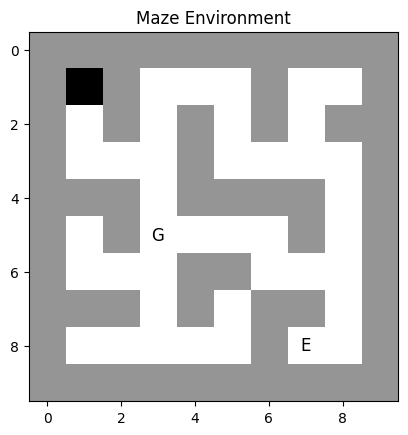

2


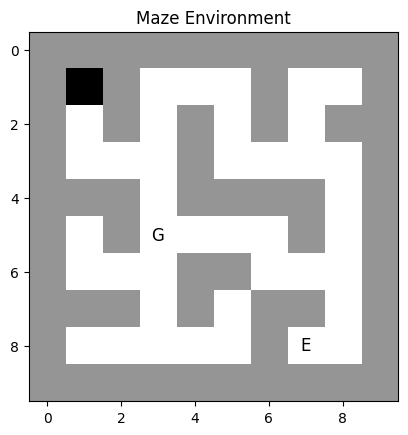

0


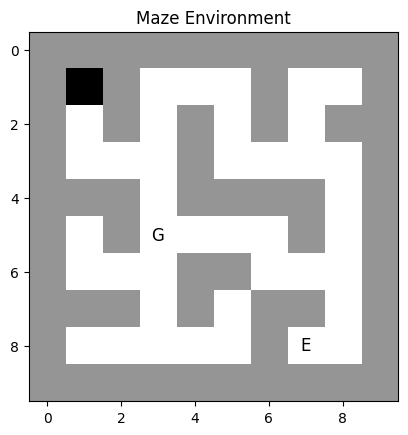

2


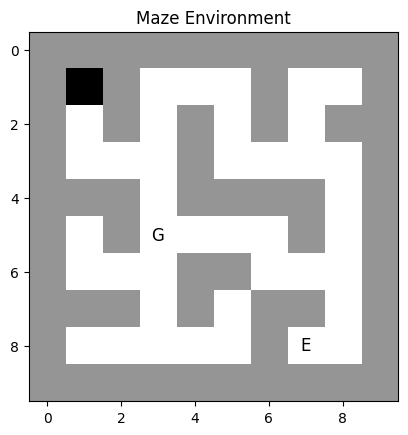

0


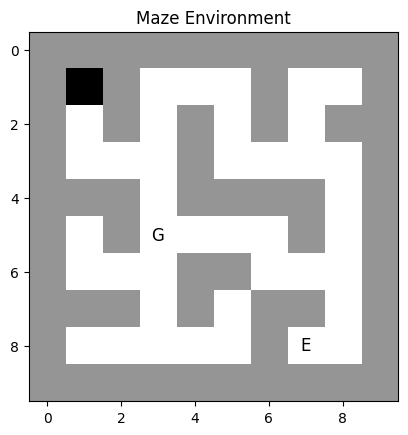

0


In [2]:
env = MazeEnv()

state = env.reset()

terminated = False

for i in range(5):

    env.render()
    action = env.action_space.sample()

    print(action)
    next_state, reward, terminated = env.step(action)


    state = next_state

    

## Get the number of states and actions

In [3]:
env = MazeEnv()

num_states = 100
num_actions = env.action_space.n

## Initialize the Q-table 

In [4]:
Q = np.zeros((num_states, num_actions))

In [5]:
reward_per_random_episode = []

## How to update the Q-table

In [6]:
def update_q_table(state, action, reward,next_state):

    old_value = Q[state,action]
    next_value = max(Q[next_state])

    new_value = (1-alpha)* old_value + alpha*(reward + (gamma*next_value))

    Q[state,action] = new_value

alpha = 0.1
gamma = 0.8

## Interaction loop

In [7]:
num_episodes = 10000
Q = np.zeros((num_states, num_actions))
for i in range(num_episodes):

    state = env.reset()
    terminated = False
    episode_reward = 0

    while not terminated:

        action = env.action_space.sample()
        next_state, reward, terminated = env.step(action)
        
        update_q_table(state,action,reward,next_state)

        episode_reward += reward

        state = next_state

    reward_per_random_episode.append(episode_reward)


print(f"This is the average reward for the random policy {np.mean(reward_per_random_episode)}")
    

This is the average reward for the random policy -778.5031


In [8]:
def get_policy():

    policy = {}

    for i in range(100):

        policy[i] = np.argmax(Q[i])

    return policy

In [9]:
print(get_policy())

{0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 1, 12: 0, 13: 1, 14: 3, 15: 1, 16: 0, 17: 1, 18: 2, 19: 0, 20: 0, 21: 1, 22: 0, 23: 1, 24: 0, 25: 1, 26: 0, 27: 1, 28: 0, 29: 0, 30: 0, 31: 3, 32: 3, 33: 1, 34: 0, 35: 3, 36: 3, 37: 3, 38: 1, 39: 0, 40: 0, 41: 0, 42: 0, 43: 1, 44: 0, 45: 0, 46: 0, 47: 0, 48: 1, 49: 0, 50: 0, 51: 1, 52: 0, 53: 3, 54: 3, 55: 3, 56: 1, 57: 0, 58: 1, 59: 0, 60: 0, 61: 3, 62: 3, 63: 0, 64: 0, 65: 0, 66: 3, 67: 3, 68: 1, 69: 0, 70: 0, 71: 0, 72: 0, 73: 0, 74: 0, 75: 1, 76: 0, 77: 0, 78: 1, 79: 0, 80: 0, 81: 3, 82: 3, 83: 0, 84: 2, 85: 2, 86: 0, 87: 0, 88: 2, 89: 0, 90: 0, 91: 0, 92: 0, 93: 0, 94: 0, 95: 0, 96: 0, 97: 0, 98: 0, 99: 0}


## Interaction with the learned deterministic policy

In [11]:
rewards_learned_policy = []

In [12]:
num_episodes = 10000
for i in range(num_episodes):

    state = env.reset()
    terminated = False
    episode_reward = 0

    while not terminated:

        action = get_policy()[state]
        next_state, reward, terminated = env.step(action)

        episode_reward += reward

        state = next_state


    rewards_learned_policy.append(episode_reward)


print(f"This is the average reward for the random policy {np.mean(rewards_learned_policy)}")
    

This is the average reward for the random policy 89.0


## Learned policy with the stochastic option

In [13]:
rewards_learned_policy_stochastic = []

In [14]:
num_episodes = 10000
epsilon = 0.1
for i in range(num_episodes):

    state = env.reset()
    terminated = False
    episode_reward = 0

    while not terminated:

        if np.random.rand() > 0.1:
            action = get_policy()[state]
        else:
            action = env.action_space.sample()

        next_state, reward, terminated = env.step(action)

        episode_reward += reward

        state = next_state

    rewards_learned_policy_stochastic.append(episode_reward)


print(f"This is the average reward for the random policy {np.mean(rewards_learned_policy_stochastic)}")
    

This is the average reward for the random policy 87.6079


## Analysis

Analysis Ideas:- 

1) We are going to analyze the differnece in the performance of the Learned Q-values using a determinstic and stochastic policies.

- Hypothesis:- The Deterministic Policy performs better than the Stochastic Policy.

2) How changing the value of the sub-goal changes the behavior of the algorithm.

- Hypothesis:- Making the value of the sub-goal higher than the normal states, makes the algorithm consider it in its learned optimal path.

3) How the alpha and gamma values change the performance of the algorithm.

- Hypothesis:- I got no idea ngl


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
average_rewards = [np.mean(rewards_learned_policy_stochastic), np.mean(rewards_learned_policy)]
categories = ['Stochastic Policy', 'Determinsitic Policy']

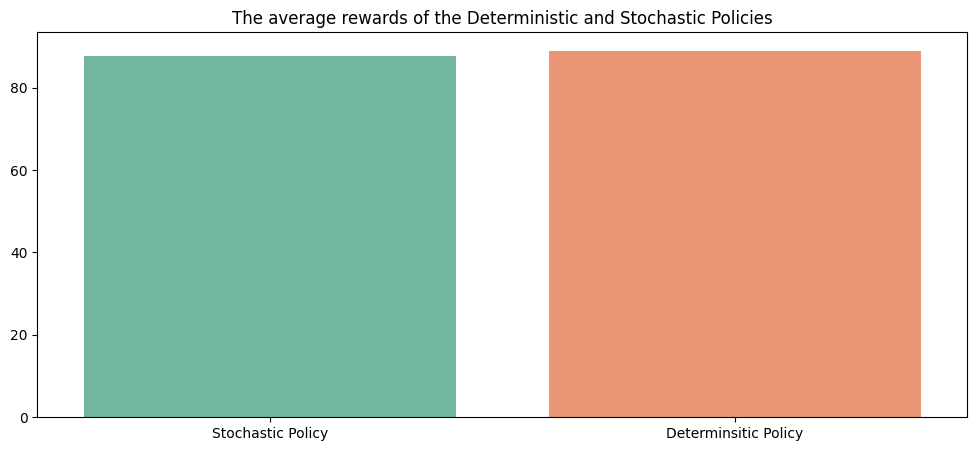

In [31]:
plt.figure(figsize=(12,5))
sns.barplot(x=categories, y=average_rewards, palette="Set2", hue=categories, legend=False)
plt.title("The average rewards of the Deterministic and Stochastic Policies")
plt.show()
